# EuroSAT Land-Use Classification with a CNN

For this project, we will use the EuroSAT dataset.

The dataset contains 10 classes:

AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial,
Pasture, PermanentCrop, Residential, River and SeaLake.

The images are RGB satellite images.

In Stage 1, we will:
- load the EuroSAT dataset
- create training, validation and test sets
- visualize some images
- define a CNN from scratch
- train the CNN
- evaluate its performance
- save the trained model


In [2]:
import torch
import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np

import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim


In [3]:
torch.manual_seed(42)


In [4]:
classes = (
    'AnnualCrop',
    'Forest',
    'HerbaceousVegetation',
    'Highway',
    'Industrial',
    'Pasture',
    'PermanentCrop',
    'Residential',
    'River',
    'SeaLake'
)

print(classes)


('AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake')


In [5]:
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

dataset = torchvision.datasets.EuroSAT(
    root='./data',
    download=True,
    transform=transform
)

print(dataset)


Dataset EuroSAT
    Number of datapoints: 27000
    Root location: ./data
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )


In [6]:
print("Number of images:", len(dataset))
print("Classes:", dataset.classes)


Number of images: 27000
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [7]:
train_size = int(0.70 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset, test_dataset = torch.utils.data.random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=generator
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))


Training images: 18900
Validation images: 4050
Test images: 4050


In [8]:
batch_size = 64

trainloader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

valloader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

testloader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created")


DataLoaders created


In [9]:
dataiter = iter(trainloader)
images, labels = next(dataiter)

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)


Image batch shape: torch.Size([64, 3, 64, 64])
Label batch shape: torch.Size([64])


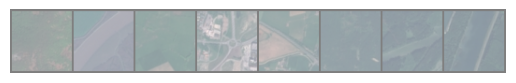

GroundTruth:           Forest           River         Pasture         Highway         Highway          Forest           River           River


In [10]:
def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis('off')
    plt.show()

imshow(torchvision.utils.make_grid(images[:8]))

print(
    'GroundTruth: ',
    ' '.join('%15s' % classes[labels[j]] for j in range(8))
)


In [11]:
class Net(nn.Module):

    def __init__(self):
        super(Net, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)

        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = self.pool(F.relu(self.conv3(x)))

        x = x.view(-1, 128 * 8 * 8)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


In [12]:
net = Net()

print(net)


Net(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=8192, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)


In [13]:
total_params = sum(p.numel() for p in net.parameters())

print("Total parameters:", total_params)


Total parameters: 2193226


In [14]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    net.parameters(),
    lr=0.001
)


In [16]:
n_epochs = 10

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(n_epochs):

    running_loss = 0.0
    correct = 0
    total = 0

    # Training
    net.train()

    for i, data in enumerate(trainloader, 0):

        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        # statistics
        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(trainloader)
    train_accuracy = correct / total

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    # Validation
    net.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for data in valloader:

            images, labels = data

            outputs = net(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(valloader)
    val_accuracy = correct / total

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        '[%d] train loss: %.3f | train accuracy: %.2f%% | '
        'validation loss: %.3f | validation accuracy: %.2f%%'
        % (
            epoch + 1,
            train_loss,
            100 * train_accuracy,
            val_loss,
            100 * val_accuracy
        )
    )

print('Finished Training')


[1] train loss: 1.139 | train accuracy: 56.87% | validation loss: 0.734 | validation accuracy: 72.74%
[2] train loss: 0.672 | train accuracy: 75.42% | validation loss: 0.745 | validation accuracy: 72.57%
[3] train loss: 0.582 | train accuracy: 78.81% | validation loss: 0.579 | validation accuracy: 78.79%
[4] train loss: 0.488 | train accuracy: 82.10% | validation loss: 0.501 | validation accuracy: 82.44%
[5] train loss: 0.443 | train accuracy: 83.80% | validation loss: 0.464 | validation accuracy: 83.68%
[6] train loss: 0.392 | train accuracy: 86.13% | validation loss: 0.439 | validation accuracy: 83.85%
[7] train loss: 0.333 | train accuracy: 88.09% | validation loss: 0.414 | validation accuracy: 86.12%
[8] train loss: 0.278 | train accuracy: 90.10% | validation loss: 0.446 | validation accuracy: 84.59%
[9] train loss: 0.261 | train accuracy: 90.63% | validation loss: 0.418 | validation accuracy: 86.35%
[10] train loss: 0.215 | train accuracy: 92.26% | validation loss: 0.421 | validat

In [17]:
PATH = './baseline.pth'

torch.save(net.state_dict(), PATH)

print("Model saved as:", PATH)


Model saved as: ./baseline.pth


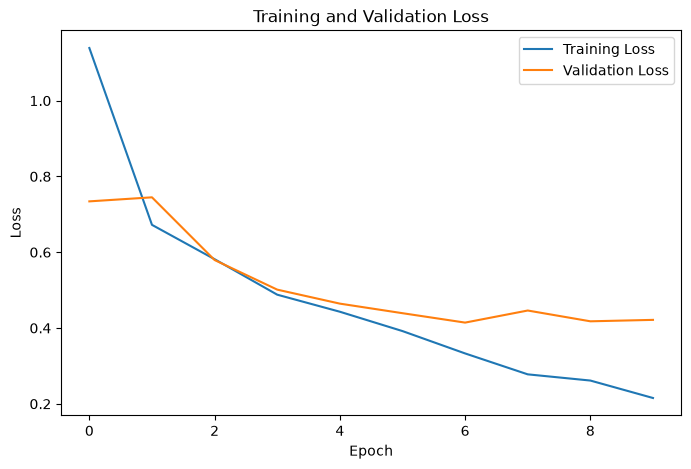

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.title('Training and Validation Loss')

plt.legend()

plt.show()


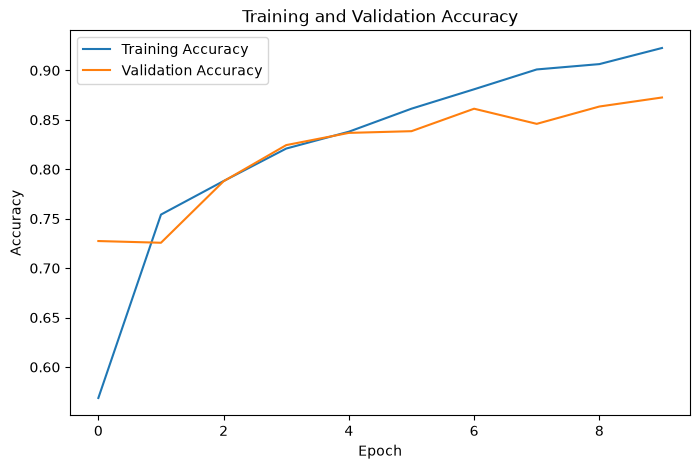

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.title('Training and Validation Accuracy')

plt.legend()

plt.show()


In [22]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print(device)


cpu


In [23]:
PATH = './baseline.pth'

trainednet = Net()

trainednet.load_state_dict(
    torch.load(PATH, map_location=device)
)

trainednet = trainednet.to(device)


In [24]:
correct = 0
total = 0

with torch.no_grad():

    for data in testloader:

        images, labels = data

        outputs = trainednet(images)

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

print(
    'Accuracy of the network on the test images: %d %%'
    % (100 * correct / total)
)


Accuracy of the network on the test images: 87 %


In [26]:
class_correct = list(0. for i in range(10))
class_total = list(0. for i in range(10))

with torch.no_grad():

    for data in testloader:

        images, labels = data

        images = images.to(device)
        labels = labels.to(device)

        outputs = trainednet(images)

        _, predicted = torch.max(outputs, 1)

        c = (predicted == labels)

        for i in range(len(labels)):

            label = labels[i]

            class_correct[label] += c[i].item()
            class_total[label] += 1


In [27]:
for i in range(10):

    print(
        'Accuracy of %25s : %2d %%'
        % (
            classes[i],
            100 * class_correct[i] / class_total[i]
        )
    )


Accuracy of                AnnualCrop : 90 %
Accuracy of                    Forest : 98 %
Accuracy of      HerbaceousVegetation : 83 %
Accuracy of                   Highway : 80 %
Accuracy of                Industrial : 85 %
Accuracy of                   Pasture : 80 %
Accuracy of             PermanentCrop : 76 %
Accuracy of               Residential : 97 %
Accuracy of                     River : 80 %
Accuracy of                   SeaLake : 93 %


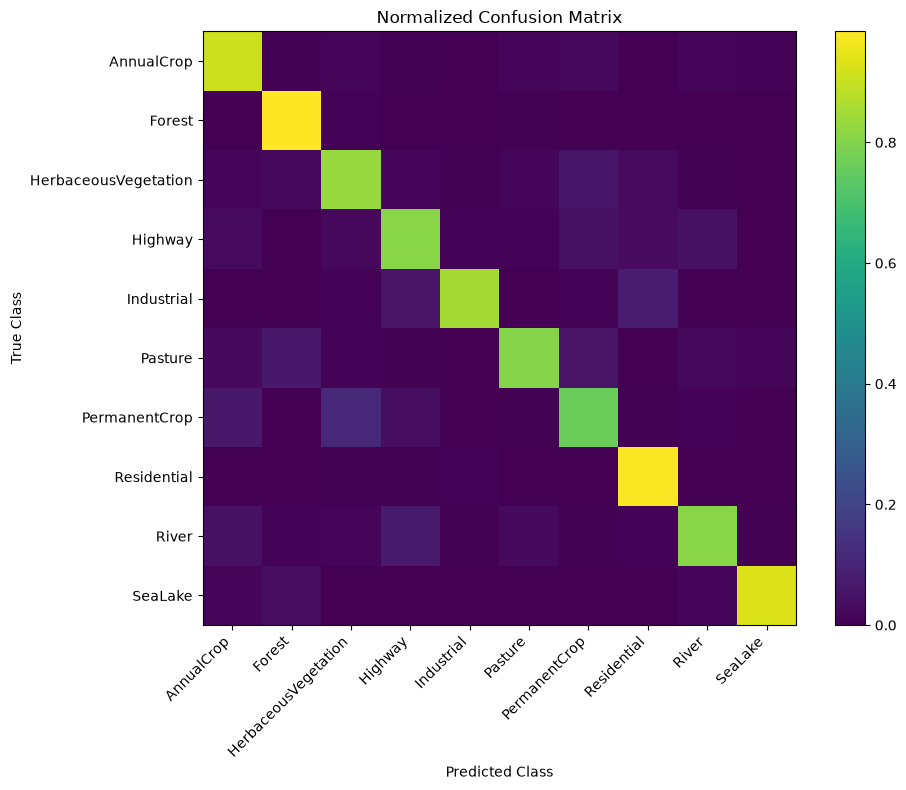

In [28]:
from sklearn.metrics import confusion_matrix

all_labels = []
all_predictions = []

trainednet.eval()

with torch.no_grad():

    for data in testloader:

        images, labels = data

        images = images.to(device)

        outputs = trainednet(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())

cm = confusion_matrix(
    all_labels,
    all_predictions,
    normalize='true'
)

plt.figure(figsize=(10, 8))

plt.imshow(cm)

plt.colorbar()

plt.xticks(
    range(10),
    classes,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(10),
    classes
)

plt.xlabel('Predicted Class')
plt.ylabel('True Class')

plt.title('Normalized Confusion Matrix')

plt.tight_layout()

plt.show()


In [30]:
print("===================================")
print("STAGE 1 - BASELINE RESULTS")
print("===================================")

print("Model: Baseline CNN")
print("Classes:", len(classes))
print("Batch size:", batch_size)
print("Epochs:", n_epochs)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Total parameters:", total_params)

print(
    "Best validation accuracy: %.2f%%"
    % (100 * max(val_accuracies))
)

print(
    "Final test accuracy: %.2f%%"
    % (100 * correct / total)
)

print("Checkpoint: baseline.pth")


STAGE 1 - BASELINE RESULTS
Model: Baseline CNN
Classes: 10
Batch size: 64
Epochs: 10
Optimizer: Adam
Learning rate: 0.001
Total parameters: 2193226
Best validation accuracy: 87.26%
Final test accuracy: 87.26%
Checkpoint: baseline.pth


# Stage 2 — Controlled CNN Architecture Experiments

The purpose of Stage 2 is to evaluate how key architectural choices affect EuroSAT classification performance while keeping the training procedure fixed.

The controlled experiments examine:

- network depth;
- convolution kernel size;
- Batch Normalization;
- convolution stride;
- convolution padding.

The Stage 1 baseline is reused as the control configuration. The test set is **not** used for model selection in Stage 2; all comparisons are based on validation performance.


### Experimental Control

To ensure a fair comparison, the following settings remain fixed across Stage 2: the EuroSAT split, preprocessing, batch size, loss function, Adam optimizer, learning rate, epoch count, and validation procedure. Only the intended architectural factor is changed in each experiment.


## 2.1 — Stage 2 Setup

Import the small additional libraries needed to measure runtime, save checkpoints, and build the final comparison table.


In [9]:
import os
import time
import pandas as pd

os.makedirs('./checkpoints', exist_ok=True)
os.makedirs('./results', exist_ok=True)

device = torch.device("cpu")
n_epochs = 10
print("Stage 2 device:", device)


Stage 2 device: cpu


**What to understand:**
- All Stage 2 experiments run on the same laptop and CPU.
- Using one machine also makes the runtime comparison more meaningful.


## 2.2 — Stage 1 Baseline Reference

The completed Stage 1 model is the control configuration: three convolutional layers, 3×3 kernels, stride 1, padding 1, and no Batch Normalization.

It is not retrained here.


In [10]:
baseline_result = {
    'Model': 'Baseline (Stage 1)',
    'Change': '3 conv / 3x3 / no BN / stride 1 / padding 1',
    'Parameters': 2193226,
    'Best Epoch': 10,
    'Peak Val Accuracy (%)': 87.26,
    'Train Accuracy at Best (%)': 92.26,
    'Generalization Gap (%)': 5.00,
    'Runtime (min)': None,
    'Latency (ms/image)': None,
    'Checkpoint': 'baseline.pth'
}

print(baseline_result)


{'Model': 'Baseline (Stage 1)', 'Change': '3 conv / 3x3 / no BN / stride 1 / padding 1', 'Parameters': 2193226, 'Best Epoch': 10, 'Peak Val Accuracy (%)': 87.26, 'Train Accuracy at Best (%)': 92.26, 'Generalization Gap (%)': 5.0, 'Runtime (min)': None, 'Latency (ms/image)': None, 'Checkpoint': 'baseline.pth'}


## 2.3 — Fair DataLoader Creation

Each independent experiment uses the same training and validation subsets.  
A fixed generator is used when the training loader is recreated so that the shuffle order is reproducible.


In [11]:
def make_stage2_loaders():

    loader_generator = torch.Generator().manual_seed(42)

    stage2_trainloader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        generator=loader_generator
    )

    stage2_valloader = torch.utils.data.DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    return stage2_trainloader, stage2_valloader


**What to understand:**
- The training/validation split is exactly the same as Stage 1.
- Only the architecture is changed in Stage 2.


## 2.4 — Shared Stage 2 Training Function

The same basic PyTorch training procedure is reused for every architecture: forward pass, loss calculation, backpropagation, optimizer step, and validation.

The best checkpoint is saved according to validation accuracy.


In [12]:
def train_stage2_model(model, model_name, change, checkpoint_name):

    torch.manual_seed(42)

    model = model.to(device)

    stage2_trainloader, stage2_valloader = make_stage2_loaders()

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    train_losses = []
    train_accuracies = []
    val_losses = []
    val_accuracies = []

    best_val_accuracy = 0.0
    best_train_accuracy = 0.0
    best_epoch = 0

    checkpoint_path = os.path.join(
        './checkpoints',
        checkpoint_name
    )

    start_time = time.time()

    for epoch in range(n_epochs):

        # Training
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in stage2_trainloader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(stage2_trainloader)
        train_accuracy = correct / total

        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)

        # Validation
        model.eval()

        running_val_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in stage2_valloader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                running_val_loss += loss.item()

                _, predicted = torch.max(outputs.data, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_loss = running_val_loss / len(stage2_valloader)
        val_accuracy = correct / total

        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        print(
            '%s | Epoch [%d/%d] | Train Loss: %.4f | Train Acc: %.2f%% | '
            'Val Loss: %.4f | Val Acc: %.2f%%'
            % (
                model_name,
                epoch + 1,
                n_epochs,
                train_loss,
                100 * train_accuracy,
                val_loss,
                100 * val_accuracy
            )
        )

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy
            best_train_accuracy = train_accuracy
            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

    runtime_seconds = time.time() - start_time

    # Load the best model before measuring inference latency
    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device
        )
    )

    model.eval()

    images, _ = next(iter(stage2_valloader))
    images = images.to(device)

    repetitions = 10

    latency_start = time.perf_counter()

    with torch.no_grad():

        for _ in range(repetitions):
            model(images)

    latency_seconds = time.perf_counter() - latency_start

    latency_ms_per_image = (
        latency_seconds * 1000
        / repetitions
        / images.size(0)
    )

    total_params = sum(
        p.numel()
        for p in model.parameters()
    )

    generalization_gap = 100 * (
        best_train_accuracy - best_val_accuracy
    )

    result = {
        'Model': model_name,
        'Change': change,
        'Parameters': total_params,
        'Best Epoch': best_epoch,
        'Peak Val Accuracy (%)': round(100 * best_val_accuracy, 2),
        'Train Accuracy at Best (%)': round(100 * best_train_accuracy, 2),
        'Generalization Gap (%)': round(generalization_gap, 2),
        'Runtime (min)': round(runtime_seconds / 60, 2),
        'Latency (ms/image)': round(latency_ms_per_image, 4),
        'Checkpoint': checkpoint_name
    }

    history = {
        'train_loss': train_losses,
        'train_accuracy': train_accuracies,
        'val_loss': val_losses,
        'val_accuracy': val_accuracies
    }

    print()
    print("Finished:", model_name)
    print(result)
    print()

    return result, history


**What to understand:**
- `optimizer.zero_grad()` clears old gradients.
- `loss.backward()` computes new gradients.
- `optimizer.step()` updates the weights.
- Validation uses `model.eval()` and `torch.no_grad()` because no learning happens during validation.


# 2.5 — Network Depth Experiments

This experiment compares the Stage 1 three-layer baseline with a shallower two-layer CNN and a deeper four-layer CNN while keeping all training settings unchanged.


### 2.5.1 — Two-Layer CNN

This network removes one convolutional block from the baseline.


In [13]:
class Depth2Net(nn.Module):

    def __init__(self):
        super(Depth2Net, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.fc1 = nn.Linear(64 * 16 * 16, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = x.view(-1, 64 * 16 * 16)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


### 2.5.2 — Four-Layer CNN

This network adds one convolutional block to the baseline.


In [14]:
class Depth4Net(nn.Module):

    def __init__(self):
        super(Depth4Net, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)

        self.conv4 = nn.Conv2d(128, 256, 3, padding=1)

        self.fc1 = nn.Linear(256 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = self.pool(F.relu(self.conv3(x)))

        x = self.pool(F.relu(self.conv4(x)))

        x = x.view(-1, 256 * 4 * 4)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


# 2.6 — Kernel Size Experiments

This experiment keeps the same three-layer baseline structure and changes only the convolution kernel size.

The Stage 1 3×3 model is used as the control, while the new experiments evaluate 5×5 and 7×7 kernels.


### 2.6.1 — Configurable Kernel CNN

Padding is adjusted to keep the feature-map size unchanged before pooling.


In [15]:
class KernelNet(nn.Module):

    def __init__(self, kernel_size):
        super(KernelNet, self).__init__()

        padding = kernel_size // 2

        self.conv1 = nn.Conv2d(
            3,
            32,
            kernel_size,
            padding=padding
        )

        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(
            32,
            64,
            kernel_size,
            padding=padding
        )

        self.conv3 = nn.Conv2d(
            64,
            128,
            kernel_size,
            padding=padding
        )

        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = self.pool(F.relu(self.conv3(x)))

        x = x.view(-1, 128 * 8 * 8)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


**What to understand:** A larger kernel sees a larger local region of the image, but it also increases the number of convolution parameters.


# 2.7 — Batch Normalization, Stride, and Padding Experiments

Three controlled architectural changes are evaluated separately:

1. adding Batch Normalization after each convolution;
2. changing the first convolution stride from 1 to 2;
3. changing the first convolution padding from 1 to 0.

Each modification is tested independently against the Stage 1 baseline.


### 2.7.1 — Batch Normalization CNN

BatchNorm is added after each convolution and before ReLU.


In [16]:
class BatchNormNet(nn.Module):

    def __init__(self):
        super(BatchNormNet, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(
            F.relu(self.bn1(self.conv1(x)))
        )

        x = self.pool(
            F.relu(self.bn2(self.conv2(x)))
        )

        x = self.pool(
            F.relu(self.bn3(self.conv3(x)))
        )

        x = x.view(-1, 128 * 8 * 8)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


### 2.7.2 — Stride-2 CNN

Only the first convolution stride is changed from 1 to 2.


In [17]:
class Stride2Net(nn.Module):

    def __init__(self):
        super(Stride2Net, self).__init__()

        self.conv1 = nn.Conv2d(
            3,
            32,
            3,
            stride=2,
            padding=1
        )

        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)

        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = self.pool(F.relu(self.conv3(x)))

        x = x.view(-1, 128 * 4 * 4)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


### 2.7.3 — Padding-0 CNN

Only the first convolution padding is changed from 1 to 0.


In [18]:
class Padding0Net(nn.Module):

    def __init__(self):
        super(Padding0Net, self).__init__()

        self.conv1 = nn.Conv2d(
            3,
            32,
            3,
            padding=0
        )

        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)

        self.fc1 = nn.Linear(128 * 7 * 7, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = self.pool(F.relu(self.conv3(x)))

        x = x.view(-1, 128 * 7 * 7)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


# 2.8 — Stage 2 Experiment Execution

This cell runs all seven new Stage 2 experiments sequentially using the same training configuration.

The test set is not evaluated during these experiments. Each model is selected only according to validation accuracy, and the best checkpoint for each configuration is saved automatically.


In [19]:
stage2_results = [
    baseline_result
]

stage2_histories = {}


# --------------------------------------------------
# Network depth experiments
# --------------------------------------------------

torch.manual_seed(42)

result, history = train_stage2_model(
    Depth2Net(),
    'Depth 2',
    '2 convolutional layers',
    'stage2_depth2.pth'
)

stage2_results.append(result)
stage2_histories['Depth 2'] = history


torch.manual_seed(42)

result, history = train_stage2_model(
    Depth4Net(),
    'Depth 4',
    '4 convolutional layers',
    'stage2_depth4.pth'
)

stage2_results.append(result)
stage2_histories['Depth 4'] = history


# --------------------------------------------------
# Kernel size experiments
# --------------------------------------------------

torch.manual_seed(42)

result, history = train_stage2_model(
    KernelNet(kernel_size=5),
    'Kernel 5x5',
    '5x5 kernels',
    'stage2_kernel5.pth'
)

stage2_results.append(result)
stage2_histories['Kernel 5x5'] = history


torch.manual_seed(42)

result, history = train_stage2_model(
    KernelNet(kernel_size=7),
    'Kernel 7x7',
    '7x7 kernels',
    'stage2_kernel7.pth'
)

stage2_results.append(result)
stage2_histories['Kernel 7x7'] = history


# --------------------------------------------------
# BatchNorm / stride / padding experiments
# --------------------------------------------------

torch.manual_seed(42)

result, history = train_stage2_model(
    BatchNormNet(),
    'BatchNorm',
    'BatchNorm after each convolution',
    'stage2_batchnorm.pth'
)

stage2_results.append(result)
stage2_histories['BatchNorm'] = history


torch.manual_seed(42)

result, history = train_stage2_model(
    Stride2Net(),
    'Stride 2',
    'First convolution stride = 2',
    'stage2_stride2.pth'
)

stage2_results.append(result)
stage2_histories['Stride 2'] = history


torch.manual_seed(42)

result, history = train_stage2_model(
    Padding0Net(),
    'Padding 0',
    'First convolution padding = 0',
    'stage2_padding0.pth'
)

stage2_results.append(result)
stage2_histories['Padding 0'] = history


print("===================================")
print("STAGE 2 TRAINING FINISHED")
print("===================================")


Depth 2 | Epoch [1/10] | Train Loss: 1.1505 | Train Acc: 57.12% | Val Loss: 0.7861 | Val Acc: 71.56%
Depth 2 | Epoch [2/10] | Train Loss: 0.7301 | Train Acc: 73.60% | Val Loss: 0.7002 | Val Acc: 74.79%
Depth 2 | Epoch [3/10] | Train Loss: 0.5884 | Train Acc: 78.67% | Val Loss: 0.6700 | Val Acc: 75.63%
Depth 2 | Epoch [4/10] | Train Loss: 0.5123 | Train Acc: 81.50% | Val Loss: 0.5494 | Val Acc: 80.32%
Depth 2 | Epoch [5/10] | Train Loss: 0.4563 | Train Acc: 83.68% | Val Loss: 0.5159 | Val Acc: 81.56%
Depth 2 | Epoch [6/10] | Train Loss: 0.3966 | Train Acc: 85.62% | Val Loss: 0.5464 | Val Acc: 79.43%
Depth 2 | Epoch [7/10] | Train Loss: 0.3376 | Train Acc: 87.96% | Val Loss: 0.4892 | Val Acc: 83.31%
Depth 2 | Epoch [8/10] | Train Loss: 0.2803 | Train Acc: 89.77% | Val Loss: 0.5427 | Val Acc: 82.74%
Depth 2 | Epoch [9/10] | Train Loss: 0.2505 | Train Acc: 91.18% | Val Loss: 0.5505 | Val Acc: 81.38%
Depth 2 | Epoch [10/10] | Train Loss: 0.2063 | Train Acc: 92.76% | Val Loss: 0.5183 | Val A

## 2.9 — Stage 2 Benchmark Table

Combine the Stage 1 baseline and all seven Stage 2 experiments into one benchmark table containing parameter count, peak validation accuracy, generalization gap, runtime, latency, and checkpoint information.


In [20]:
stage2_table = pd.DataFrame(stage2_results)

stage2_table = stage2_table.sort_values(
    by='Peak Val Accuracy (%)',
    ascending=False
).reset_index(drop=True)

display(stage2_table)

stage2_table.to_csv(
    './results/stage2_architecture_results.csv',
    index=False
)

print(
    "Results saved as:",
    "./results/stage2_architecture_results.csv"
)


,Model,Change,Parameters,Best Epoch,Peak Val Accuracy (%),Train Accuracy at Best (%),Generalization Gap (%),Runtime (min),Latency (ms/image),Checkpoint
0,BatchNorm,BatchNorm after each convolution,2193674,6,88.67,88.68,0.01,18.68,2.0336,stage2_batchnorm.pth
1,Depth 4,4 convolutional layers,1439818,8,87.60,86.92,-0.69,18.53,2.0001,stage2_depth4.pth
2,Baseline (Stage 1),3 conv / 3x3 / no BN / stride 1 / padding 1,2193226,10,87.26,92.26,5.00,NaN,NaN,baseline.pth
3,Padding 0,First convolution padding = 0,1701706,7,84.77,85.18,0.41,14.34,1.5328,stage2_padding0.pth
4,Depth 2,2 convolutional layers,4216522,10,83.88,92.76,8.88,17.09,1.3033,stage2_depth2.pth
5,Kernel 5x5,5x5 kernels,2358602,10,83.41,89.84,6.43,23.40,2.5951,stage2_kernel5.pth
6,Stride 2,First convolution stride = 2,620362,10,81.93,83.94,2.02,6.47,0.4426,stage2_stride2.pth
7,Kernel 7x7,7x7 kernels,2606666,9,79.41,81.81,2.40,381.41,3.8455,stage2_kernel7.pth


Results saved as: ./results/stage2_architecture_results.csv


## 2.10 — Peak Validation Accuracy Comparison

Plot the peak validation accuracy of all Stage 2 configurations.  
The best architecture will be selected from validation results and then carried forward to Stage 3.


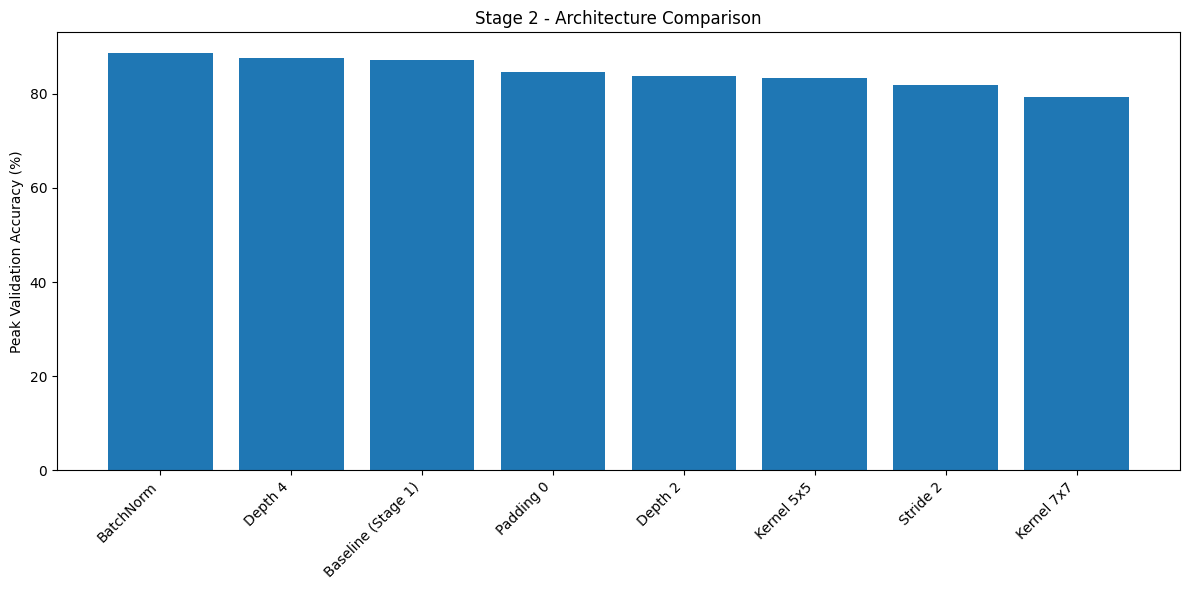

In [21]:
plt.figure(figsize=(12, 6))

plt.bar(
    stage2_table['Model'],
    stage2_table['Peak Val Accuracy (%)']
)

plt.xticks(
    rotation=45,
    ha='right'
)

plt.ylabel('Peak Validation Accuracy (%)')
plt.title('Stage 2 - Architecture Comparison')

plt.tight_layout()
plt.show()


## 2.11 — Validation Accuracy Curves

Plot the validation-accuracy curves of the seven new experiments.  
The Stage 1 baseline peak is shown as a horizontal reference line.


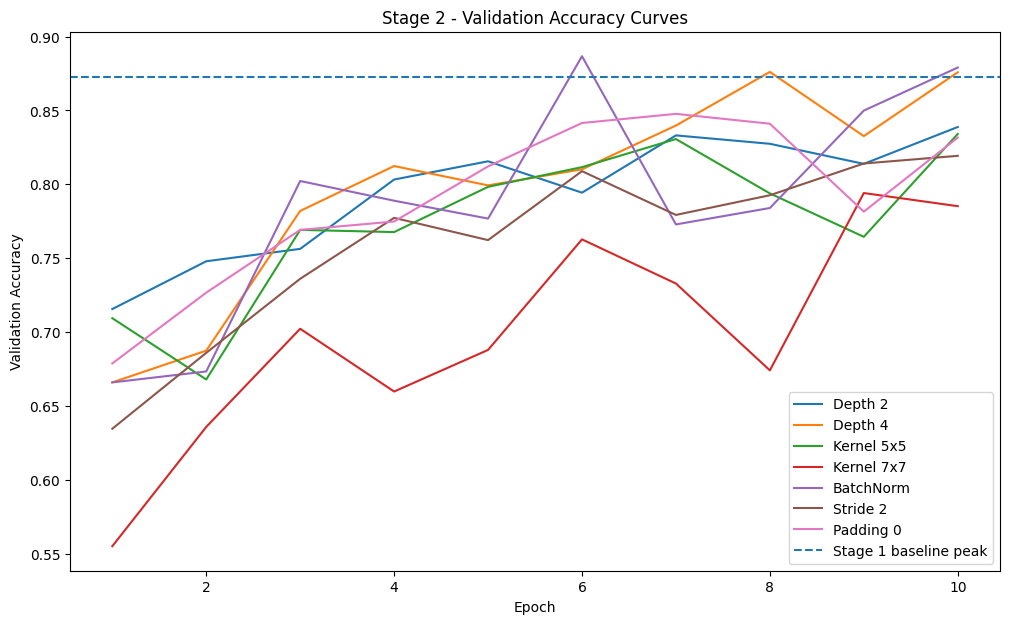

In [22]:
plt.figure(figsize=(12, 7))

for name, history in stage2_histories.items():

    plt.plot(
        range(1, n_epochs + 1),
        history['val_accuracy'],
        label=name
    )

plt.axhline(
    y=0.8726,
    linestyle='--',
    label='Stage 1 baseline peak'
)

plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.title('Stage 2 - Validation Accuracy Curves')

plt.legend()
plt.show()


## 2.12 — Stage 2 Summary and Selection Criterion

The architecture selected for Stage 3 should be chosen from the validation results only.

The decision should consider peak validation accuracy together with model complexity, generalization gap, runtime, and inference latency. The test set remains reserved for later final evaluation.


### Stage 2 Summary

Stage 2 evaluated several controlled CNN architecture variations while keeping the dataset split, preprocessing, batch size, optimizer, learning rate, loss function, and number of epochs fixed. The experiments investigated network depth, kernel size, Batch Normalization, stride, and padding.

The **BatchNorm model achieved the highest peak validation accuracy of 88.67% at epoch 6**, improving on the Stage 1 baseline accuracy of **87.26%**. It also achieved a very small generalization gap of **0.01%**, while adding only a small number of parameters compared with the baseline.

Increasing the network depth to four convolutional layers also produced a strong result of **87.60% validation accuracy**, but it did not outperform the BatchNorm model. Reducing the depth to two convolutional layers decreased validation accuracy to **83.88%**.

Increasing the convolution kernel size did not improve performance. The 5×5 model reached **83.41%**, while the 7×7 model reached only **79.41%** and required substantially more computation. The 7×7 runtime was unusually high compared with the other experiments and is therefore treated as an observed runtime anomaly rather than a normal timing result.

Changing the first convolution stride to 2 greatly reduced the number of parameters and produced the lowest inference latency, but validation accuracy decreased to **81.93%**. Removing padding from the first convolution produced **84.77%** validation accuracy, which was also below the baseline.

Based primarily on validation accuracy, while also considering generalization, parameter count, runtime, and inference latency, the **three-layer CNN with 3×3 kernels, stride 1, padding 1, and Batch Normalization was selected as the architecture for Stage 3**.

The test set was not used during Stage 2 and remains reserved for final model evaluation.